# Entrenamiento de CNN ResNet-18 con Transfer Learning
## Objetivos

- Construir un modelo baseline de clasificación mediante transfer learning con ResNet18 preentrenada.
- Entrenar inicialmente solo la capa clasificadora y descongelar `layer4` en `UNFREEZE_EPOCH` con una tasa de aprendizaje menor.
- Aplicar transformaciones y aumentación de datos al conjunto de entrenamiento.
- Entrenar y validar el modelo registrando loss y accuracy por época.
- Evaluar el modelo de la última época sobre el conjunto de prueba.
- Analizar los resultados mediante accuracy, precision, recall, F1-score, reporte de clasificación y matriz de confusión normalizada.
- Guardar los pesos finales del modelo entrenado.

In [1]:
# Importaciones
import matplotlib.pyplot as plt

from vasijas.paths import ProjectPaths, ruta_relativa
from vasijas.config import load_config
from vasijas.metadata import cargar_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    calcular_resultado_clasificacion,
    crear_criterio_entropia_cruzada,
    crear_dataloaders_imagen_desde_metadata,
    crear_modelo_transfer_learning,
    crear_optimizador_adam,
    describir_dispositivo,
    describir_metricas_epoch,
    entrenar_modelo,
    graficar_historial_entrenamiento,
    graficar_lote_imagenes,
    graficar_matriz_confusion,
    guardar_pesos_modelo,
    seleccionar_dispositivo_procesamiento,
    validar_modelo,
)

In [2]:
# Configuracion general
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)

## Dispositivo para procesamiento

In [3]:
DEVICE = seleccionar_dispositivo_procesamiento()
print(describir_dispositivo(DEVICE))

Dispositivo utilizado para procesamiento: CUDA - NVIDIA GeForce GTX 1650


In [4]:
# Parámetros

# Clases
CLASES_A_PROCESAR = [*range(1, 12)]

# Modelo
MODEL_NAME = "resnet18"
RUN_NAME = "default"

# Entrenamiento
BATCH_SIZE = 16
EPOCHS = 30
LR = 1e-3
UNFREEZE_EPOCH = 4  # Índice desde cero
BACKBONE_LR_FACTOR = 0.1
BACKBONE_LR = LR * BACKBONE_LR_FACTOR

# Preprocesamiento
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Aumentación de datos
FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.7, 1.0)
ROTATION_DEGREES = 15
PIXEL_FILL = (255, 255, 255)

# Datos de entrada y división persistida
DATA_DIR = PATHS.DATA_UNIFICADO_DIVIDIDO

In [5]:
# Parameters
DATASET_NAME = "unificado"
MODEL_NAME = "resnet18"
BATCH_SIZE = 16
EPOCHS = 300
LR = 0.0001
ENABLE_UNFREEZE = True
UNFREEZE_EPOCH = 10
BACKBONE_LR_FACTOR = 0.1
USE_CLASS_WEIGHTS = True
ENABLE_HORIZONTAL_FLIP = True
FLIP_PROBABILITY = 0.5
ENABLE_ROTATION = True
ROTATION_DEGREES = [-15, 15]
ENABLE_SCALING = True
SCALING_FACTOR_INTERVAL = [0.8, 1.0]
IMG_SIZE = 224
PIXEL_FILL = [255, 255, 255]
SEED = 42
TEST_VAL_FRACTION = 0.3
TEST_FRACTION_OF_TEMP = 0.5
NUM_WORKERS = 8
USE_AMP = True
USE_CHANNELS_LAST = True
ENABLE_MODEL_COMPILE = False
RUN_NAME = "bs16_lr1e-4_flip05_weighted_unfreeze"


## División de datos

La pertenencia de cada imagen a `train`, `val` o `test` se lee de la metadata generada por el notebook de división. La relación se realiza mediante `ruta_relativa`; por tanto, el split no se recalcula aunque cambien la semilla o los parámetros del entrenamiento.

In [6]:
# Metadata, transformaciones y dataloaders
metadata_split = cargar_metadata(DATA_DIR)

config_transformaciones = ConfiguracionTransformacionesImagen(
    tamano_imagen=IMG_SIZE,
    probabilidad_flip=FLIP_PROBABILITY,
    intervalo_escalado=SCALING_FACTOR_INTERVAL,
    grados_rotacion=ROTATION_DEGREES,
    relleno_pixeles=PIXEL_FILL,
    media_normalizacion=IMAGENET_MEAN,
    desvio_normalizacion=IMAGENET_STD,
)

dataloaders = crear_dataloaders_imagen_desde_metadata(
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    batch_size=BATCH_SIZE,
    configuracion_transformaciones=config_transformaciones,
)

train_loader = dataloaders.train
val_loader = dataloaders.val
test_loader = dataloaders.test
class_names = dataloaders.class_names
NUM_CLASSES = dataloaders.num_classes

print(f"Metadata de split: {ruta_relativa(DATA_DIR / 'metadata.csv')}")
print("Clases:", *class_names)
print(
    f"Split persistido -> train: {len(train_loader.dataset)}, "
    f"val: {len(val_loader.dataset)}, "
    f"test: {len(test_loader.dataset)}"
)

Metadata de split: data/12.unificado_divididos_en_train_val_y_test/metadata.csv
Clases: clase01 clase02 clase03 clase05 clase06 clase07 clase08 clase09 clase10 clase11
Split persistido -> train: 14231, val: 3059, test: 3059


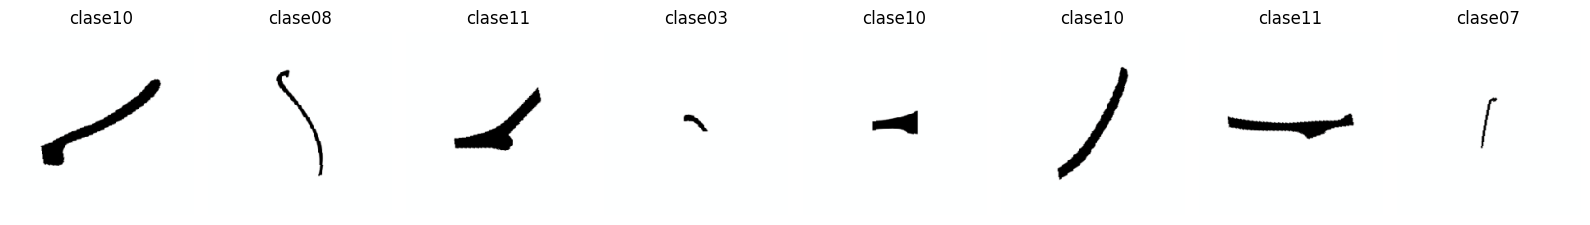

In [7]:
# Visualización rápida (sanity check)
graficar_lote_imagenes(loader=train_loader, nombres_clases=class_names, cantidad=8)
plt.show()

model = crear_modelo_transfer_learning(
    nombre_modelo=MODEL_NAME,
    num_classes=NUM_CLASSES,
    dispositivo=DEVICE,
)

In [8]:
# Criterio y optimizador
criterion = crear_criterio_entropia_cruzada()
optimizer = crear_optimizador_adam(model, learning_rate=LR)

In [9]:
# Entrenamiento y validación
historial = entrenar_modelo(
    modelo=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterio=criterion,
    optimizador=optimizer,
    dispositivo=DEVICE,
    epochs=EPOCHS,
    model_name=MODEL_NAME,
    unfreeze_epoch=UNFREEZE_EPOCH,
    backbone_lr=BACKBONE_LR,
    al_finalizar_epoch=lambda metrica: print(
        describir_metricas_epoch(metrica, total_epochs=EPOCHS)
    ),
)

Epoch 1/300
Train Loss: 1.6631 | Train Acc: 0.4591 | Val Loss: 1.6097 | Val Acc: 0.4861
Tiempo de epoch: 0:01:27.332375 



Epoch 2/300
Train Loss: 1.4281 | Train Acc: 0.5314 | Val Loss: 1.5054 | Val Acc: 0.4956
Tiempo de epoch: 0:01:24.154321 



Epoch 3/300
Train Loss: 1.3345 | Train Acc: 0.5616 | Val Loss: 1.4708 | Val Acc: 0.4956
Tiempo de epoch: 0:01:24.401773 



Epoch 4/300
Train Loss: 1.2904 | Train Acc: 0.5778 | Val Loss: 1.4221 | Val Acc: 0.5270
Tiempo de epoch: 0:01:24.211146 



Epoch 5/300
Train Loss: 1.2494 | Train Acc: 0.5917 | Val Loss: 1.4189 | Val Acc: 0.5057
Tiempo de epoch: 0:01:24.411044 



Epoch 6/300
Train Loss: 1.2167 | Train Acc: 0.6056 | Val Loss: 1.3802 | Val Acc: 0.5221
Tiempo de epoch: 0:01:24.140213 



... (290 outputs left out)

Epoch 297/300
Train Loss: 0.0984 | Train Acc: 0.9613 | Val Loss: 1.0950 | Val Acc: 0.8012
Tiempo de epoch: 0:01:56.123599 



Epoch 298/300
Train Loss: 0.0892 | Train Acc: 0.9649 | Val Loss: 0.9949 | Val Acc: 0.8137
Tiempo de epoch: 0:01:56.132473 



Epoch 299/300
Train Loss: 0.0939 | Train Acc: 0.9627 | Val Loss: 1.0539 | Val Acc: 0.8137
Tiempo de epoch: 0:01:56.235524 



Epoch 300/300
Train Loss: 0.1031 | Train Acc: 0.9602 | Val Loss: 0.9542 | Val Acc: 0.8195
Tiempo de epoch: 0:01:56.346052 



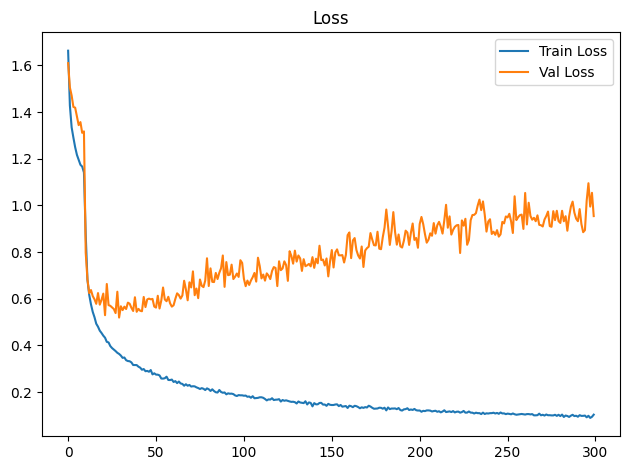

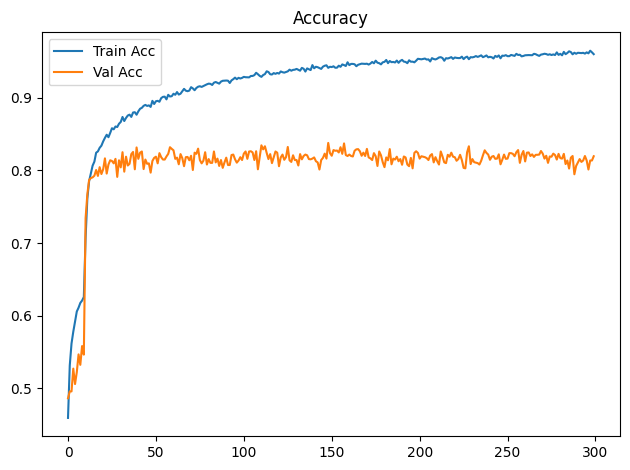

In [10]:
# Curvas de entrenamiento
graficar_historial_entrenamiento(historial)
plt.show()

Test Acc: 0.8127
              precision    recall  f1-score   support

     clase01       0.76      0.84      0.80        76
     clase02       0.55      0.36      0.43       133
     clase03       0.77      0.69      0.73       209
     clase05       0.76      0.86      0.80       152
     clase06       0.79      0.53      0.64       152
     clase07       0.88      0.91      0.90       133
     clase08       0.79      0.89      0.84       798
     clase09       0.45      0.33      0.38        57
     clase10       0.89      0.93      0.91      1007
     clase11       0.79      0.68      0.73       342

    accuracy                           0.81      3059
   macro avg       0.74      0.70      0.72      3059
weighted avg       0.81      0.81      0.81      3059



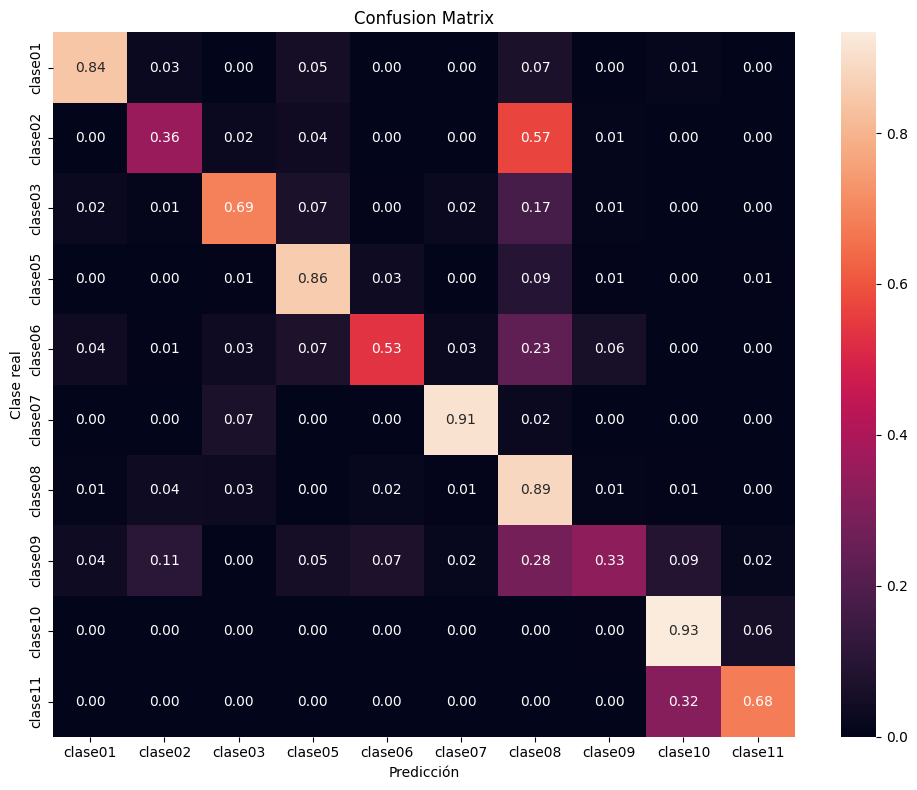

In [11]:
# Evaluación final
resultado_test = validar_modelo(
    modelo=model,
    loader=test_loader,
    criterio=criterion,
    dispositivo=DEVICE,
)
resultado_clasificacion = calcular_resultado_clasificacion(
    resultado=resultado_test,
    nombres_clases=class_names,
)

print(f"Test Acc: {resultado_test.accuracy:.4f}")
print(resultado_clasificacion.reporte)

graficar_matriz_confusion(
    matriz=resultado_clasificacion.matriz_confusion,
    nombres_clases=class_names,
)
plt.show()

In [12]:
# Guardado del modelo
ruta_modelo = guardar_pesos_modelo(
    modelo=model,
    ruta_destino=PATHS.OUTPUT_MODELS / f"model_{MODEL_NAME}_{RUN_NAME}.pth",
)
print(f"Modelo guardado en: {ruta_relativa(ruta_modelo)}")

Modelo guardado en: output/models/model_resnet18_bs16_lr1e-4_flip05_weighted_unfreeze.pth
